In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from pathlib import Path
import joblib
import json

PROJECT_ROOT = Path.cwd().parent

ARTIFACT_PATH = PROJECT_ROOT / "artifacts"
SEQUENCE_PATH = ARTIFACT_PATH / "sequences"
MODEL_PATH = ARTIFACT_PATH / "models"
METRICS_PATH = ARTIFACT_PATH / "metrics"

MODEL_PATH.mkdir(parents=True, exist_ok=True)
METRICS_PATH.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)




PyTorch: 2.15.0+cpu
Device: cpu


In [4]:
print("Project root:", PROJECT_ROOT)
print("Sequence path:", SEQUENCE_PATH)
print("Folder exists:", SEQUENCE_PATH.exists())

if SEQUENCE_PATH.exists():
    print("Files found:")
    for file in SEQUENCE_PATH.iterdir():
        print(file.name)

Project root: c:\projects\Electricity-Forecasting-AD
Sequence path: c:\projects\Electricity-Forecasting-AD\artifacts\sequences
Folder exists: True
Files found:
test_sequences.npz
train_sequences.npz
validation_sequences.npz


In [5]:
train_data = np.load(SEQUENCE_PATH / "train_sequences.npz", allow_pickle=True)
val_data = np.load(SEQUENCE_PATH / "validation_sequences.npz", allow_pickle=True)
test_data = np.load(SEQUENCE_PATH / "test_sequences.npz", allow_pickle=True)

X_train = train_data["X"]
y_train = train_data["y"]
base_train = train_data["baseline"]

X_val = val_data["X"]
y_val = val_data["y"]
base_val = val_data["baseline"]

X_test = test_data["X"]
y_test = test_data["y"]
base_test = test_data["baseline"]

time_test = test_data["timestamps"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nFirst test timestamp:", time_test[0])

Training: (94478, 96, 7) (94478,)
Validation: (20204, 96, 7) (20204,)
Testing: (20205, 96, 7) (20205,)

First test timestamp: 2010-04-19 17:45:00


In [6]:
scaler = joblib.load(ARTIFACT_PATH / "scaler.pkl")

target_idx = list(scaler.feature_names_in_).index("Global_active_power")

target_mean = scaler.mean_[target_idx]
target_scale = scaler.scale_[target_idx]

print("Target:", "Global_active_power")
print("Training mean:", target_mean)
print("Training standard deviation:", target_scale)

Target: Global_active_power
Training mean: 1.086228668429413
Training standard deviation: 1.023089581103349


In [7]:
def inverse_target(values):
    return values * target_scale + target_mean

y_test_actual = inverse_target(y_test)
baseline_test_actual = inverse_target(base_test)

print("Actual consumption range:",
      y_test_actual.min(), "to", y_test_actual.max())

print("Baseline prediction range:",
      baseline_test_actual.min(), "to", baseline_test_actual.max())

Actual consumption range: 0.14386668856080242 to 7.76786684925723
Baseline prediction range: 0.14386668856080242 to 7.76786684925723


In [8]:
baseline_mae = mean_absolute_error(
    y_test_actual, baseline_test_actual
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test_actual, baseline_test_actual)
)

baseline_r2 = r2_score(
    y_test_actual, baseline_test_actual
)

baseline_results = {
    "Model": "Persistence Baseline",
    "MAE (kW)": baseline_mae,
    "RMSE (kW)": baseline_rmse,
    "R2": baseline_r2
}

display(pd.DataFrame([baseline_results]))

print(f"MAE:  {baseline_mae:.4f} kW")
print(f"RMSE: {baseline_rmse:.4f} kW")
print(f"R²:   {baseline_r2:.4f}")

,Model,MAE (kW),RMSE (kW),R2
0,Persistence Baseline,0.290846,0.491929,0.622536


MAE:  0.2908 kW
RMSE: 0.4919 kW
R²:   0.6225


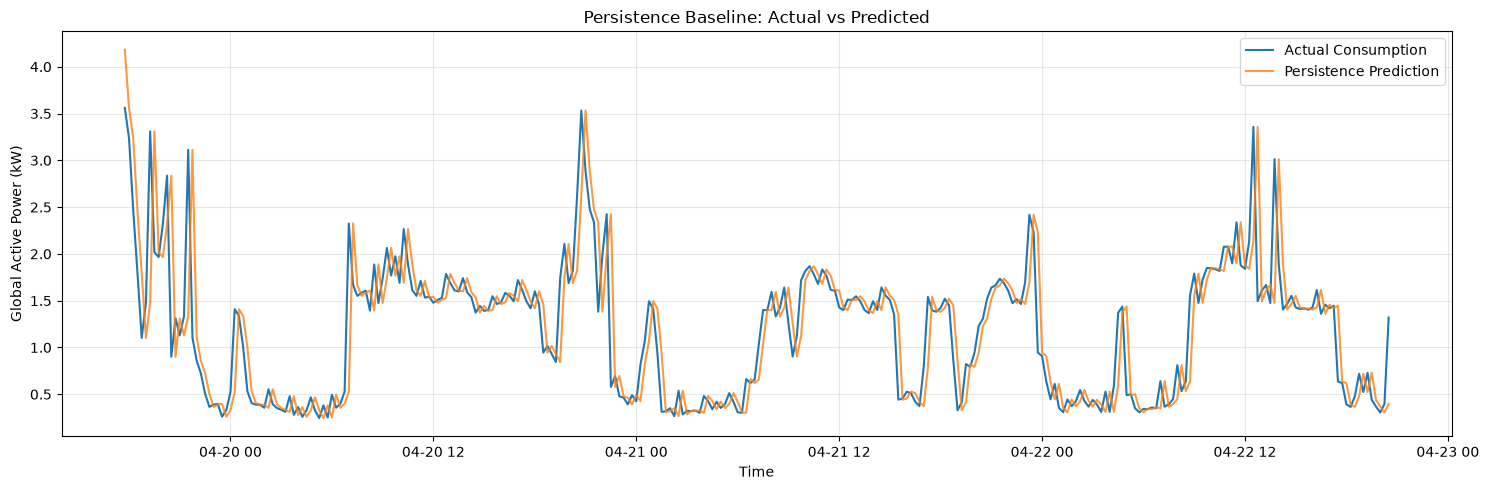

In [9]:
plt.figure(figsize=(15, 5))

plt.plot(
    time_test[:300],
    y_test_actual[:300],
    label="Actual Consumption"
)

plt.plot(
    time_test[:300],
    baseline_test_actual[:300],
    label="Persistence Prediction",
    alpha=0.8
)

plt.title("Persistence Baseline: Actual vs Predicted")
plt.xlabel("Time")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
train_data = np.load(SEQUENCE_PATH / "train_sequences.npz", allow_pickle=True)
val_data = np.load(SEQUENCE_PATH / "validation_sequences.npz", allow_pickle=True)
test_data = np.load(SEQUENCE_PATH / "test_sequences.npz", allow_pickle=True)

X_train = train_data["X"]
y_train = train_data["y"]
base_train = train_data["baseline"]

X_val = val_data["X"]
y_val = val_data["y"]
base_val = val_data["baseline"]

X_test = test_data["X"]
y_test = test_data["y"]
base_test = test_data["baseline"]

time_test = test_data["timestamps"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

print("\nFirst test timestamp:", time_test[0])

Training: (94478, 96, 7) (94478,)
Validation: (20204, 96, 7) (20204,)
Testing: (20205, 96, 7) (20205,)

First test timestamp: 2010-04-19 17:45:00


### LSTM Model


In [10]:
class ElectricityDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


train_dataset = ElectricityDataset(X_train, y_train)
val_dataset = ElectricityDataset(X_val, y_val)

BATCH_SIZE = 256

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training batches: 370
Validation batches: 79


In [11]:
class LSTMForecaster(nn.Module):
    def __init__(
        self,
        input_size=7,
        hidden_size=64,
        num_layers=2,
        dropout=0.2
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction.squeeze(-1)


lstm_model = LSTMForecaster().to(DEVICE)

print(lstm_model)

LSTMForecaster(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [12]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    lstm_model.parameters(),
    lr=0.001
)

EPOCHS = 15
PATIENCE = 3

best_val_loss = float("inf")
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": []
}

In [13]:
for epoch in range(EPOCHS):

    # Training
    lstm_model.train()
    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad()

        predictions = lstm_model(X_batch)

        loss = criterion(predictions, y_batch)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * len(X_batch)

    train_loss /= len(train_dataset)

    # Validation
    lstm_model.eval()
    val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            predictions = lstm_model(X_batch)

            loss = criterion(predictions, y_batch)

            val_loss += loss.item() * len(X_batch)

    val_loss /= len(val_dataset)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

    # Save best model
    if val_loss < best_val_loss:

        best_val_loss = val_loss
        epochs_without_improvement = 0

        torch.save(
            lstm_model.state_dict(),
            MODEL_PATH / "best_lstm.pth"
        )

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nBest validation loss:", best_val_loss)

Epoch [1/15] Train Loss: 0.322163 | Validation Loss: 0.248171
Epoch [2/15] Train Loss: 0.250451 | Validation Loss: 0.241961
Epoch [3/15] Train Loss: 0.243308 | Validation Loss: 0.242745
Epoch [4/15] Train Loss: 0.236446 | Validation Loss: 0.229975
Epoch [5/15] Train Loss: 0.230137 | Validation Loss: 0.220688
Epoch [6/15] Train Loss: 0.222278 | Validation Loss: 0.215202
Epoch [7/15] Train Loss: 0.217236 | Validation Loss: 0.208294
Epoch [8/15] Train Loss: 0.212464 | Validation Loss: 0.206315
Epoch [9/15] Train Loss: 0.208175 | Validation Loss: 0.209382
Epoch [10/15] Train Loss: 0.207354 | Validation Loss: 0.205562
Epoch [11/15] Train Loss: 0.203546 | Validation Loss: 0.199566
Epoch [12/15] Train Loss: 0.202395 | Validation Loss: 0.200834
Epoch [13/15] Train Loss: 0.199207 | Validation Loss: 0.197982
Epoch [14/15] Train Loss: 0.197746 | Validation Loss: 0.196569
Epoch [15/15] Train Loss: 0.196015 | Validation Loss: 0.196341

Best validation loss: 0.19634115180563771


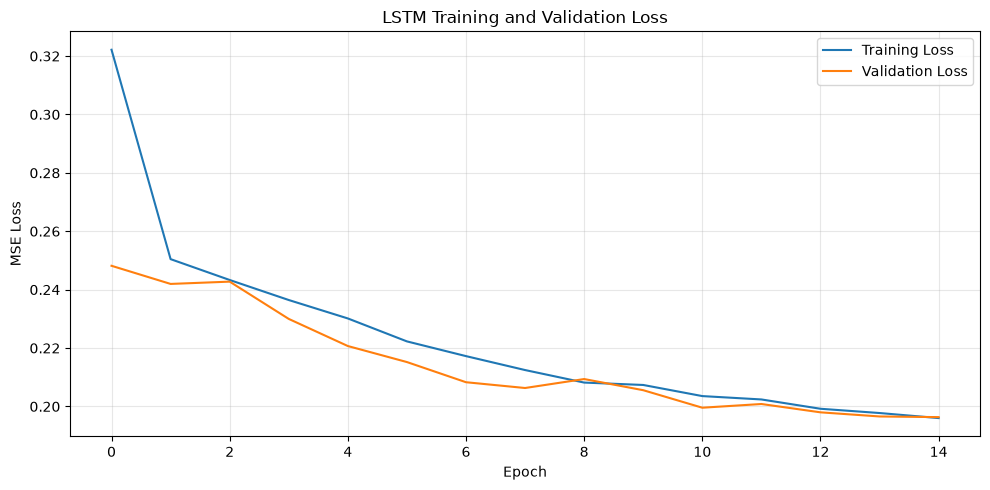

In [14]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Training Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
lstm_model.load_state_dict(
    torch.load(MODEL_PATH / "best_lstm.pth", map_location=DEVICE)
)

lstm_model.eval()

print("Best LSTM checkpoint loaded.")

Best LSTM checkpoint loaded.


In [16]:
test_dataset = ElectricityDataset(X_test, y_test)

test_loader = DataLoader(
    test_dataset,
    batch_size=256,
    shuffle=False
)

predictions = []

with torch.no_grad():
    for X_batch, _ in test_loader:
        X_batch = X_batch.to(DEVICE)

        outputs = lstm_model(X_batch)

        predictions.extend(outputs.cpu().numpy())

lstm_predictions = np.array(predictions)

print("Predictions generated:", lstm_predictions.shape)

Predictions generated: (20205,)


In [17]:
y_test_actual = inverse_target(y_test)
lstm_predictions_actual = inverse_target(lstm_predictions)

lstm_mae = mean_absolute_error(
    y_test_actual, lstm_predictions_actual
)

lstm_rmse = np.sqrt(mean_squared_error(
    y_test_actual, lstm_predictions_actual
))

lstm_r2 = r2_score(
    y_test_actual, lstm_predictions_actual
)

print(f"LSTM MAE:  {lstm_mae:.4f} kW")
print(f"LSTM RMSE: {lstm_rmse:.4f} kW")
print(f"LSTM R²:   {lstm_r2:.4f}")

LSTM MAE:  0.2458 kW
LSTM RMSE: 0.3956 kW
LSTM R²:   0.7559


In [18]:
comparison = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "MAE (kW)": baseline_mae,
        "RMSE (kW)": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "LSTM",
        "MAE (kW)": lstm_mae,
        "RMSE (kW)": lstm_rmse,
        "R2": lstm_r2
    }
])

display(comparison.round(4))

,Model,MAE (kW),RMSE (kW),R2
0,Persistence Baseline,0.2908,0.4919,0.6225
1,LSTM,0.2458,0.3956,0.7559


In [19]:
comparison.to_csv(
    METRICS_PATH / "forecasting_comparison.csv",
    index=False
)

print("LSTM and baseline results saved.")

LSTM and baseline results saved.


In [20]:
lstm_results = pd.DataFrame({
    "timestamp": time_test,
    "actual": y_test_actual,
    "predicted": lstm_predictions_actual
})

lstm_results.to_csv(
    METRICS_PATH / "lstm_test_predictions.csv",
    index=False
)

print("LSTM test predictions saved.")

LSTM test predictions saved.


### GRU

In [21]:
class GRUForecaster(nn.Module):
    def __init__(self, input_size=7, hidden_size=64, num_layers=2, dropout=0.2):
        super().__init__()

        self.gru = nn.GRU(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout
        )

        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.gru(x)
        last_output = output[:, -1, :]
        prediction = self.fc(last_output)

        return prediction.squeeze(-1)


gru_model = GRUForecaster().to(DEVICE)

print(gru_model)

GRUForecaster(
  (gru): GRU(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)


In [22]:
gru_criterion = nn.MSELoss()

gru_optimizer = torch.optim.Adam(
    gru_model.parameters(),
    lr=0.001
)

EPOCHS = 15
PATIENCE = 3

best_gru_val_loss = float("inf")
patience_counter = 0

history_gru = {
    "train_loss": [],
    "val_loss": []
}

In [23]:
for epoch in range(EPOCHS):

    # Training
    gru_model.train()

    train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        gru_optimizer.zero_grad()

        predictions = gru_model(X_batch)
        loss = gru_criterion(predictions, y_batch)

        loss.backward()
        gru_optimizer.step()

        train_loss += loss.item() * X_batch.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation
    gru_model.eval()

    val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)

            predictions = gru_model(X_batch)
            loss = gru_criterion(predictions, y_batch)

            val_loss += loss.item() * X_batch.size(0)

    val_loss /= len(val_loader.dataset)

    history_gru["train_loss"].append(train_loss)
    history_gru["val_loss"].append(val_loss)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {train_loss:.6f} | "
        f"Validation Loss: {val_loss:.6f}"
    )

    # Save best model
    if val_loss < best_gru_val_loss:

        best_gru_val_loss = val_loss
        patience_counter = 0

        torch.save(
            gru_model.state_dict(),
            MODEL_PATH / "best_gru.pth"
        )

    else:
        patience_counter += 1

    # Early stopping
    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

print("\nBest GRU validation loss:", best_gru_val_loss)

Epoch [1/15] Train Loss: 0.303599 | Validation Loss: 0.250436
Epoch [2/15] Train Loss: 0.252262 | Validation Loss: 0.245179
Epoch [3/15] Train Loss: 0.246152 | Validation Loss: 0.239714
Epoch [4/15] Train Loss: 0.241254 | Validation Loss: 0.234220
Epoch [5/15] Train Loss: 0.234562 | Validation Loss: 0.224640
Epoch [6/15] Train Loss: 0.227532 | Validation Loss: 0.219432
Epoch [7/15] Train Loss: 0.220769 | Validation Loss: 0.211409
Epoch [8/15] Train Loss: 0.216182 | Validation Loss: 0.206366
Epoch [9/15] Train Loss: 0.210837 | Validation Loss: 0.202562
Epoch [10/15] Train Loss: 0.206760 | Validation Loss: 0.197480
Epoch [11/15] Train Loss: 0.202675 | Validation Loss: 0.198803
Epoch [12/15] Train Loss: 0.200461 | Validation Loss: 0.194032
Epoch [13/15] Train Loss: 0.197996 | Validation Loss: 0.193294
Epoch [14/15] Train Loss: 0.195575 | Validation Loss: 0.196170
Epoch [15/15] Train Loss: 0.194455 | Validation Loss: 0.200244

Best GRU validation loss: 0.19329444546613145


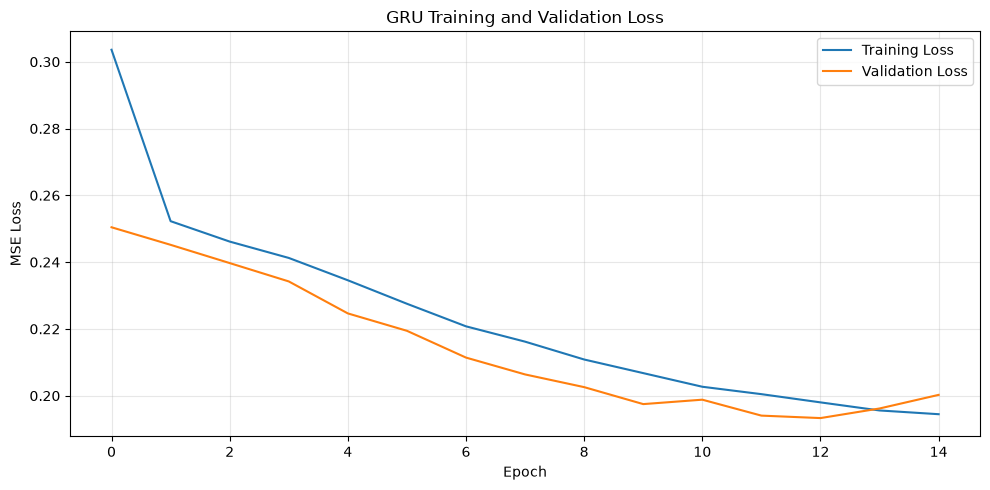

In [24]:
plt.figure(figsize=(10, 5))

plt.plot(history_gru["train_loss"], label="Training Loss")
plt.plot(history_gru["val_loss"], label="Validation Loss")

plt.title("GRU Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
gru_model.load_state_dict(
    torch.load(
        MODEL_PATH / "best_gru.pth",
        map_location=DEVICE
    )
)

gru_model.eval()

gru_predictions = []

with torch.no_grad():

    for X_batch, _ in test_loader:

        X_batch = X_batch.to(DEVICE)

        outputs = gru_model(X_batch)

        gru_predictions.extend(outputs.cpu().numpy())

gru_predictions = np.array(gru_predictions)

gru_predictions_actual = inverse_target(gru_predictions)

gru_mae = mean_absolute_error(
    y_test_actual, gru_predictions_actual
)

gru_rmse = np.sqrt(mean_squared_error(
    y_test_actual, gru_predictions_actual
))

gru_r2 = r2_score(
    y_test_actual, gru_predictions_actual
)

print(f"GRU MAE:  {gru_mae:.4f} kW")
print(f"GRU RMSE: {gru_rmse:.4f} kW")
print(f"GRU R²:   {gru_r2:.4f}")

GRU MAE:  0.2454 kW
GRU RMSE: 0.3901 kW
GRU R²:   0.7627


In [26]:
comparison = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "MAE (kW)": baseline_mae,
        "RMSE (kW)": baseline_rmse,
        "R2": baseline_r2
    },
    {
        "Model": "LSTM",
        "MAE (kW)": lstm_mae,
        "RMSE (kW)": lstm_rmse,
        "R2": lstm_r2
    },
    {
        "Model": "GRU",
        "MAE (kW)": gru_mae,
        "RMSE (kW)": gru_rmse,
        "R2": gru_r2
    }
])

display(comparison.round(4))

,Model,MAE (kW),RMSE (kW),R2
0,Persistence Baseline,0.2908,0.4919,0.6225
1,LSTM,0.2458,0.3956,0.7559
2,GRU,0.2454,0.3901,0.7627


In [27]:
# Load timestamps for validation data
time_val = val_data["timestamps"]

# Generate predictions using the best GRU checkpoint
gru_model.eval()

val_predictions = []

with torch.no_grad():
    for X_batch, _ in val_loader:
        X_batch = X_batch.to(DEVICE)

        outputs = gru_model(X_batch)

        val_predictions.extend(outputs.cpu().numpy())

val_predictions = np.array(val_predictions)

# Convert predictions and actual values back to kW
val_actual = inverse_target(y_val)
val_predicted = inverse_target(val_predictions)

# Calculate absolute residuals
val_residuals = np.abs(val_actual - val_predicted)

print("Validation predictions:", len(val_predictions))
print(f"Mean absolute residual: {val_residuals.mean():.4f} kW")
print(f"Maximum residual: {val_residuals.max():.4f} kW")

Validation predictions: 20204
Mean absolute residual: 0.2676 kW
Maximum residual: 5.4698 kW


In [28]:
ANOMALY_PERCENTILE = 99

anomaly_threshold = np.percentile(
    val_residuals,
    ANOMALY_PERCENTILE
)

print(f"Anomaly threshold: {anomaly_threshold:.4f} kW")
print(f"Calibration percentile: {ANOMALY_PERCENTILE}")

Anomaly threshold: 1.7903 kW
Calibration percentile: 99


In [29]:
test_residuals = np.abs(
    y_test_actual - gru_predictions_actual
)

test_anomalies = test_residuals > anomaly_threshold

print("Total test observations:", len(test_anomalies))
print("Detected anomalies:", test_anomalies.sum())

print(
    "Anomaly percentage:",
    round(test_anomalies.mean() * 100, 2),
    "%"
)

Total test observations: 20205
Detected anomalies: 108
Anomaly percentage: 0.53 %


In [30]:
anomaly_results = pd.DataFrame({
    "timestamp": time_test,
    "actual_consumption": y_test_actual,
    "predicted_consumption": gru_predictions_actual,
    "absolute_residual": test_residuals,
    "is_anomaly": test_anomalies
})

anomaly_results.to_csv(
    METRICS_PATH / "gru_anomaly_results.csv",
    index=False
)

print("Anomaly results saved successfully.")

Anomaly results saved successfully.


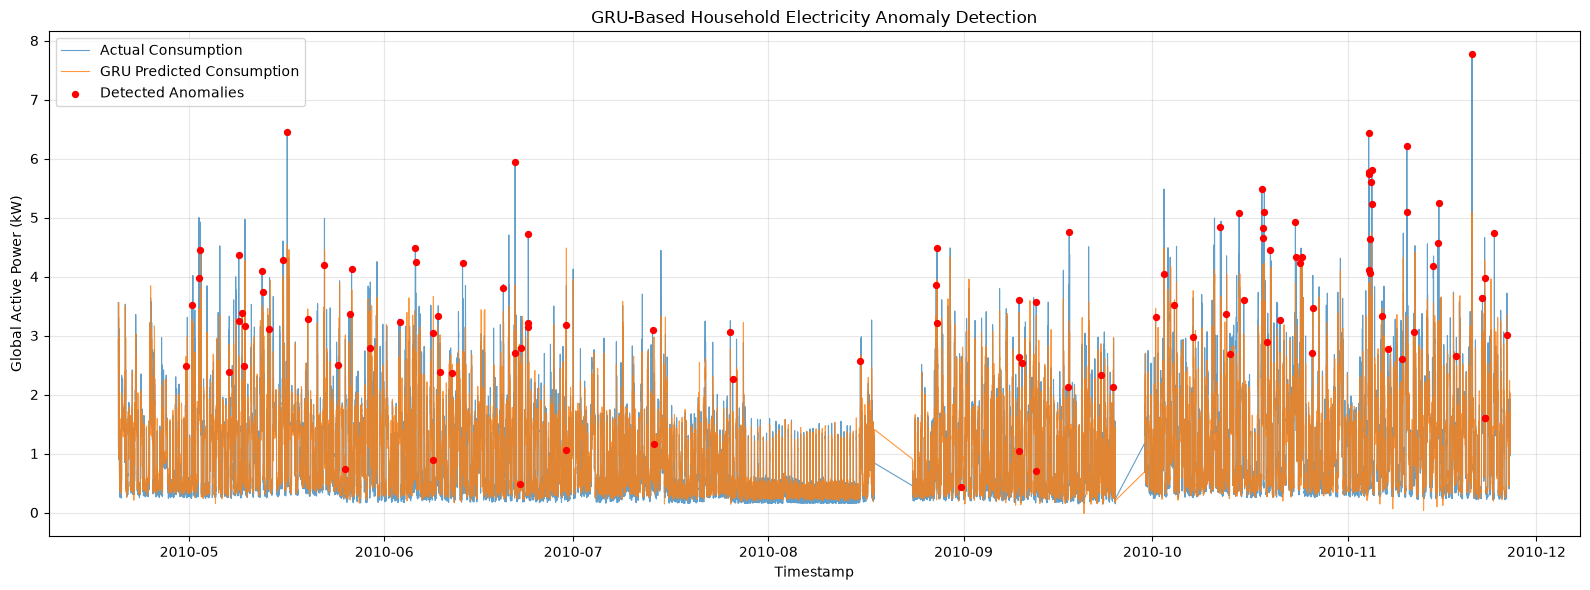

In [31]:
plt.figure(figsize=(16, 6))

plt.plot(
    time_test,
    y_test_actual,
    label="Actual Consumption",
    alpha=0.7,
    linewidth=0.8
)

plt.plot(
    time_test,
    gru_predictions_actual,
    label="GRU Predicted Consumption",
    alpha=0.8,
    linewidth=0.8
)

plt.scatter(
    time_test[test_anomalies],
    y_test_actual[test_anomalies],
    color="red",
    label="Detected Anomalies",
    s=18,
    zorder=5
)

plt.title("GRU-Based Household Electricity Anomaly Detection")
plt.xlabel("Timestamp")
plt.ylabel("Global Active Power (kW)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

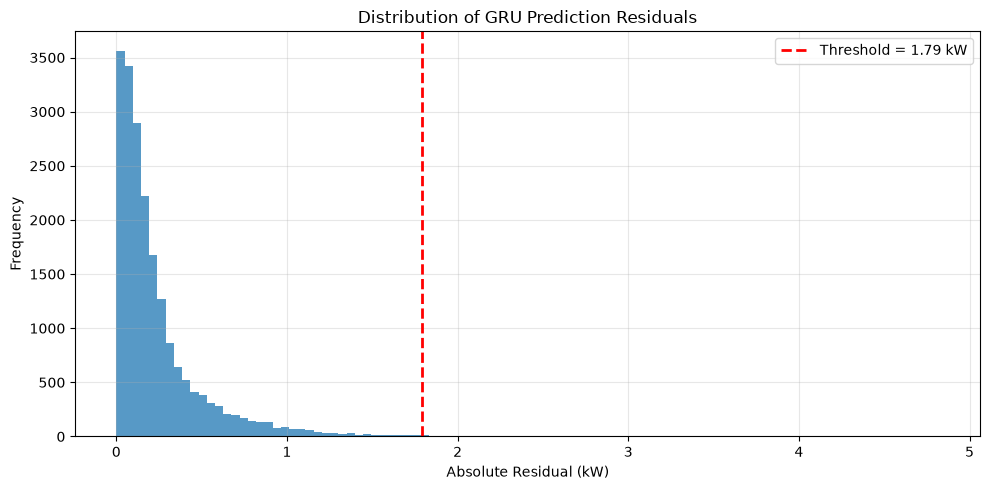

In [32]:
plt.figure(figsize=(10, 5))

plt.hist(
    test_residuals,
    bins=100,
    alpha=0.75
)

plt.axvline(
    anomaly_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Threshold = {anomaly_threshold:.2f} kW"
)

plt.title("Distribution of GRU Prediction Residuals")
plt.xlabel("Absolute Residual (kW)")
plt.ylabel("Frequency")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Test using synthetic anomaly


In [33]:
# Reproducibility
np.random.seed(42)

# Copy actual test consumption
synthetic_actual = y_test_actual.copy()

# Select 100 random positions
n_synthetic = 100

synthetic_indices = np.random.choice(
    len(synthetic_actual),
    size=n_synthetic,
    replace=False
)

# Inject artificial consumption spikes
synthetic_actual[synthetic_indices] += 2.5

print("Synthetic anomalies injected:", n_synthetic)
print("Spike magnitude: +2.5 kW")

Synthetic anomalies injected: 100
Spike magnitude: +2.5 kW


In [34]:
synthetic_residuals = np.abs(
    synthetic_actual - gru_predictions_actual
)

synthetic_detected = (
    synthetic_residuals > anomaly_threshold
)

detected_synthetic = np.sum(
    synthetic_detected[synthetic_indices]
)

missed_synthetic = n_synthetic - detected_synthetic

print("Injected anomalies:", n_synthetic)
print("Successfully detected:", detected_synthetic)
print("Missed anomalies:", missed_synthetic)

detection_rate = (
    detected_synthetic / n_synthetic
) * 100

print(f"Detection rate: {detection_rate:.2f}%")

Injected anomalies: 100
Successfully detected: 94
Missed anomalies: 6
Detection rate: 94.00%


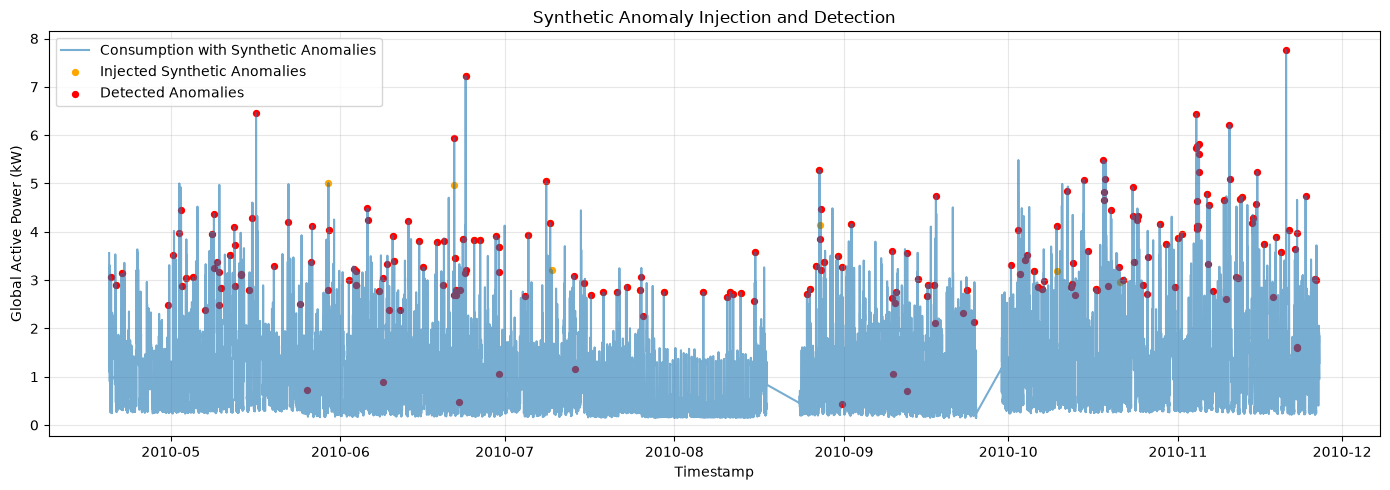

In [35]:
plt.figure(figsize=(14, 5))

plt.plot(
    time_test,
    synthetic_actual,
    label="Consumption with Synthetic Anomalies",
    alpha=0.6
)

plt.scatter(
    time_test[synthetic_indices],
    synthetic_actual[synthetic_indices],
    color="orange",
    label="Injected Synthetic Anomalies",
    s=18
)

plt.scatter(
    time_test[synthetic_detected],
    synthetic_actual[synthetic_detected],
    color="red",
    label="Detected Anomalies",
    s=18
)

plt.title("Synthetic Anomaly Injection and Detection")
plt.xlabel("Timestamp")
plt.ylabel("Global Active Power (kW)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [36]:
synthetic_results = pd.DataFrame({
    "timestamp": time_test,
    "original_consumption": y_test_actual,
    "synthetic_consumption": synthetic_actual,
    "is_injected": np.isin(
        np.arange(len(synthetic_actual)),
        synthetic_indices
    ),
    "is_detected": synthetic_detected,
    "absolute_residual": synthetic_residuals
})

synthetic_results.to_csv(
    METRICS_PATH / "synthetic_anomaly_results.csv",
    index=False
)

print("Synthetic anomaly experiment saved.")

Synthetic anomaly experiment saved.


In [37]:
synthetic_metrics = {
    "injected_anomalies": int(n_synthetic),
    "detected_anomalies": int(detected_synthetic),
    "missed_anomalies": int(missed_synthetic),
    "detection_rate_percent": float(detection_rate),
    "spike_magnitude_kw": 2.5,
    "threshold_kw": float(anomaly_threshold)
}

with open(METRICS_PATH / "synthetic_metrics.json", "w") as f:
    json.dump(synthetic_metrics, f, indent=4)

print("Synthetic experiment metrics saved.")


Synthetic experiment metrics saved.


In [38]:
print("Model files:", list(MODEL_PATH.glob("*")))
print("Metric files:", list(METRICS_PATH.glob("*")))

Model files: [WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/models/best_gru.pth'), WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/models/best_lstm.pth')]
Metric files: [WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/metrics/forecasting_comparison.csv'), WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/metrics/gru_anomaly_results.csv'), WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/metrics/lstm_test_predictions.csv'), WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/metrics/synthetic_anomaly_results.csv'), WindowsPath('c:/projects/Electricity-Forecasting-AD/artifacts/metrics/synthetic_metrics.json')]
